# 7장 · Seaborn 실습

PPT 하단의 N번호와 같은 절을 찾아 실행하세요. **모든 코드 셀은 import와 데이터 불러오기부터 독립적으로 실행**합니다.

- 데이터는 `sns.load_dataset()`으로 불러옵니다. 별도 data 폴더 대신 첫 실행의 인터넷 연결이 필요합니다.
- 각 실험의 코드 바로 뒤에 결과 해석을 적었습니다. 숫자와 그림을 함께 읽어 보세요.
- N16의 Titanic swarmplot은 점 배치 경고를 의도적으로 남긴 한계 사례입니다.

## 설치와 버전 확인

Colab에는 보통 Seaborn이 기본 설치되어 있습니다. 아래에서 버전을 먼저 확인하세요. 이 강의는 **Seaborn 0.13.x** 문법을 사용합니다. 로컬에서 설치가 필요하거나 버전이 다르면 주석 처리한 설치 명령을 실행한 뒤 커널을 다시 시작하세요.


In [1]:
# 필요한 경우에만 설치
# %pip install seaborn==0.13.2 matplotlib pandas scipy

import seaborn as sns
print("Seaborn 버전:", sns.__version__)

Matplotlib is building the font cache; this may take a moment.


Seaborn 버전: 0.13.2


## N01 · info(): 자료의 크기와 결측 확인

info()는 열 이름, 자료형, 값이 있는 기록 수를 보여 줍니다.

**질문:** 나이 그래프를 그리면 승객 891명이 모두 포함될까요?

### Titanic의 크기·열·결측치 확인

In [2]:
# N01
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

print("행과 열:", df.shape,"\n")
print(df.head(3), "\n")
df.info()
print("\n", "결측 개수:")
print(df[["age", "fare", "deck", "embark_town"]].isna().sum())
print(df["deck"].unique(),"\n")
print(df["deck"].value_counts(dropna=False))

행과 열: (891, 15) 

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare 

**결과를 읽을 때**

age의 non-null 개수와 전체 행 수가 다른 이유를 확인하세요.

### 그래프에 쓸 두 값이 모두 있는 승객 확인

In [3]:
# N01
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

used = df.dropna(subset=["age", "fare"])
print("원자료:", len(df))
print("나이와 요금이 모두 있는 기록:", len(used))
print("제외된 기록:", len(df) - len(used))
print(used[["age", "fare"]].head())

원자료: 891
나이와 요금이 모두 있는 기록: 714
제외된 기록: 177
    age     fare
0  22.0   7.2500
1  38.0  71.2833
2  26.0   7.9250
3  35.0  53.1000
4  35.0   8.0500


**결과를 읽을 때**

age와 fare가 모두 있는 기록은 714개입니다. dropna의 subset에 넣은 열만 제외 기준으로 사용합니다.

**정리**

- Titanic 자료는 891행, 15열입니다. age가 있는 기록은 714개입니다.
- 따라서 나이를 그리는 실습에는 714명이 사용됩니다.
- 갑판(deck)은 203명만 알려져 있어 해석의 범위도 이 기록에 한정합니다.

## N02 · countplot: 범주별 개수 세기

개수 막대그래프(countplot)는 각 범주에 속한 기록 수를 막대 높이로 나타냅니다.

**질문:** 자료에 남성과 여성 승객이 각각 몇 명 기록되어 있을까요?

### 성별 승객 수를 그래프로 확인

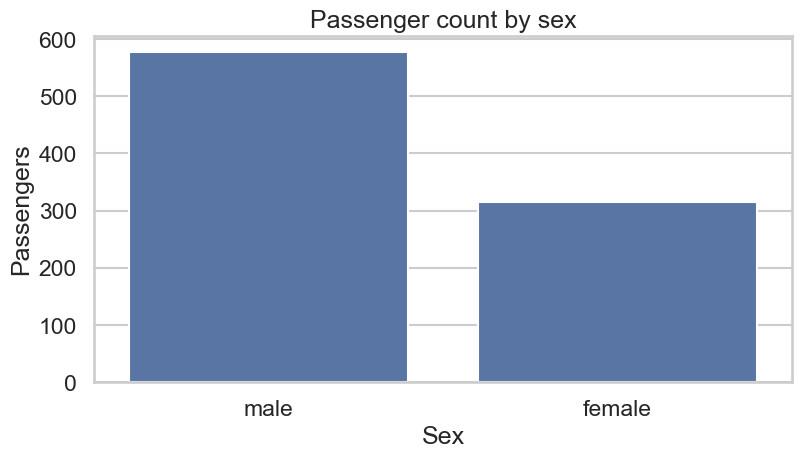

sex
male      577
female    314
Name: count, dtype: int64


In [ ]:
# N02
# 시험
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")
#subplot의 return 값 잘 보기. Figure과 Axes가 있는데 두개가 뭔지 알기
fig, ax = plt.subplots(figsize=(9, 4.5)) # 가로 9인치, 세로 4.5인치 크기의 그림 전체(fig)와 그래프 영역(ax) 생성
sns.countplot(data=df, x="sex", ax=ax) # 각 범주에 해당하는 데이터가 몇 개 있는지 세어 막대그래프로 그리는 함수

ax.set(xlabel="Sex", ylabel="Passengers", title="Passenger count by sex")

plt.show()
print(df["sex"].value_counts())

### 등급별 승객 수로 질문 바꾸기

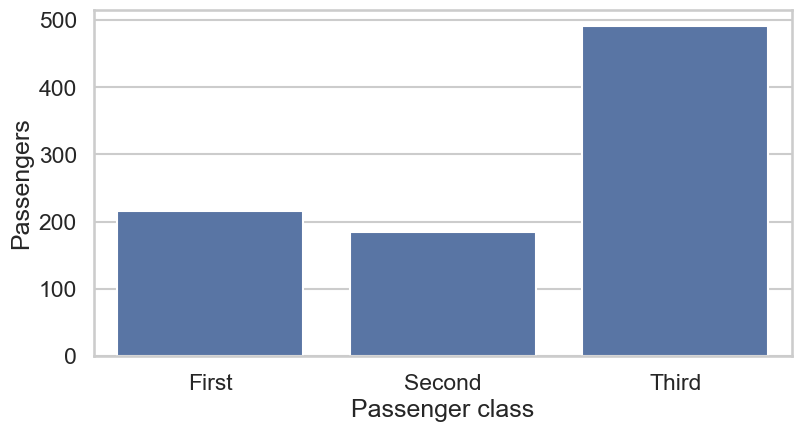

class
Third     491
First     216
Second    184
Name: count, dtype: int64


In [5]:
# N02
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="class", order=["First", "Second", "Third"], ax=ax) # order는 그래프에 범주를 나열할 순서를 지정하는 옵션입니다.
ax.set(xlabel="Passenger class", ylabel="Passengers")

plt.show()
print(df["class"].value_counts())

**정리**

- 남성 577명, 여성 314명으로 남성이 약 1.8배 많습니다.
- 막대 높이와 value_counts()의 결과가 같습니다.
- 이 집단 크기 차이는 뒤에서 생존율을 비교할 때 중요해집니다.

## N03 · countplot: hue와 palette로 집단 구분

hue는 색으로 나눌 열, palette는 각 집단에 배정할 색의 모음입니다.

**질문:** 각 성별 승객은 어느 항구에서 많이 탔을까요?

### 성별 안에서 승선 항구 비교

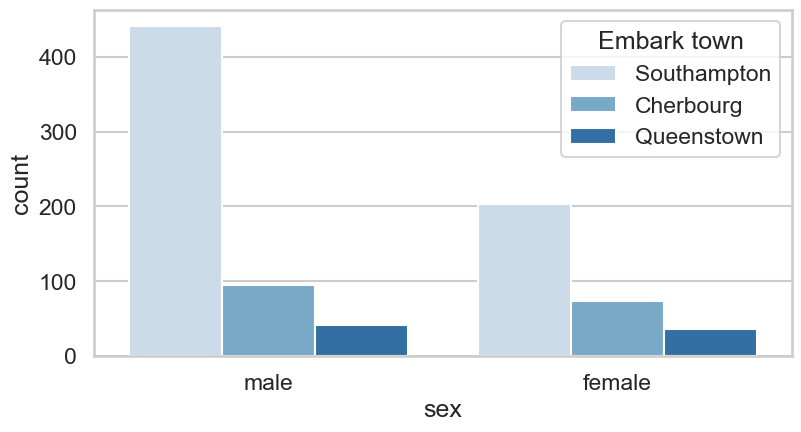

sex     embark_town
female  Cherbourg       73
        Queenstown      36
        Southampton    203
male    Cherbourg       95
        Queenstown      41
        Southampton    441
dtype: int64


In [ ]:
# N03
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="sex", # x축을 남성·여성으로 나눕니다.
              #시험 : x를 기준으로 나눈 것을 다시 embark_town으로 나눔
              # hue를 쓰면 legend가 자동으로 생성됨
              hue="embark_town", # 각 성별 안에서 승선 항구별로 다시 나누어, 다른 색의 막대로 표시합니다.
              palette="Blues", # 항구를 구분할 색으로 여러 농도의 파란색을 사용합니다.
              ax=ax)

ax.legend(title="Embark town", loc="best") # 시험 : ax.legend의 title은 단순히 텍스트 일 뿐, 실제 범례를 항구 이름과 연결한 것은 위에 hue이다.
plt.show()
print(df.groupby(["sex", "embark_town"]).size())

**결과를 읽을 때**

각 성별에서 Southampton 막대가 가장 높습니다. Blues의 진하기는 항구 이름에 배정한 색이므로 수량 순서로 해석하지 않습니다.

### 같은 자료를 구별하기 쉬운 색으로 표시

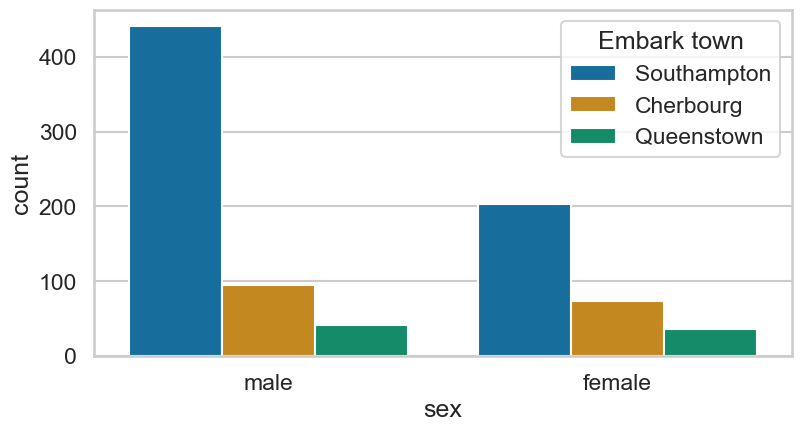

In [7]:
# N03
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="sex", hue="embark_town", palette="colorblind", ax=ax)
ax.legend(title="Embark town", loc="upper right")
plt.show()

**결과를 읽을 때**

인원수는 앞 그림과 같습니다. 항구처럼 순서 없는 범주는 colorblind의 서로 다른 색상으로 더 쉽게 구별합니다.

**정리**

- 각 성별에서 Southampton 승선자가 가장 많습니다.
- 두 그림의 인원수는 같습니다. 색 배정만 달라집니다.
- 항구에는 순서가 없으므로 colorblind처럼 서로 다른 색이 더 어울립니다.

## N04 · countplot: 생존자 수와 집단 크기

생존율은 집단의 생존자 수를 전체 승객 수로 나눈 비율입니다.

**질문:** 생존자 수가 많은 객실 등급이 생존율도 가장 높을까요?

### 등급별 생존·사망 인원수

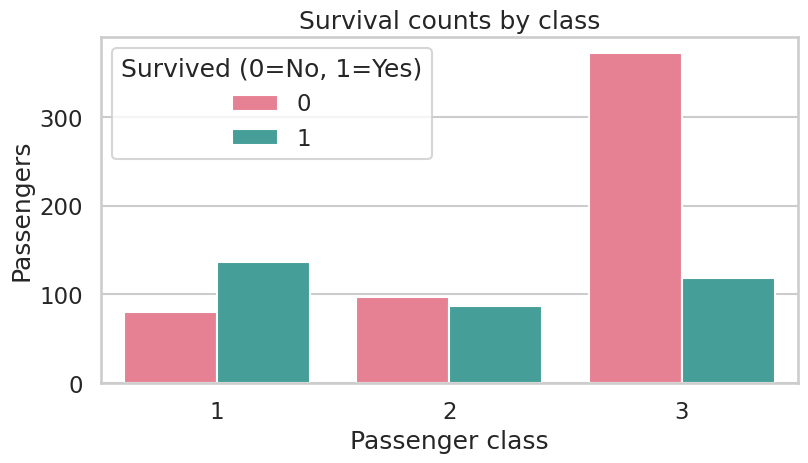

In [19]:
# N04
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="pclass", hue="survived", palette="husl", ax=ax)
ax.set(title="Survival counts by class", xlabel="Passenger class", ylabel="Passengers")
ax.legend(title="Survived (0=No, 1=Yes)", loc="best")
plt.show()

**결과를 읽을 때**

3등급의 사망자 수가 특히 많습니다. 집단 전체 크기도 크므로 생존율은 생존자 수를 해당 등급 인원으로 나누어 비교합니다.

### 분모를 맞춰 생존율 비교

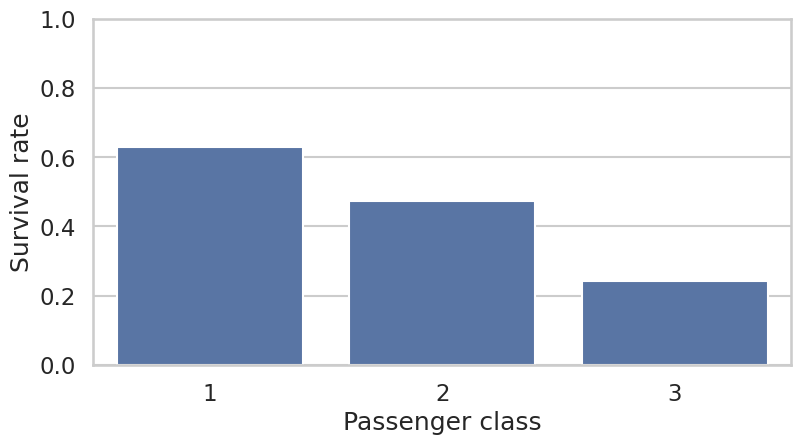

        passengers  survivors      rate
pclass                                 
1              216        136  0.629630
2              184         87  0.472826
3              491        119  0.242363


In [24]:
# N04
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="pclass", y="survived", errorbar=None, ax=ax)
ax.set(ylim=(0, 1), ylabel="Survival rate", xlabel="Passenger class")
plt.show()
print(df.groupby("pclass")["survived"].agg(passengers="size", survivors="sum", rate="mean"))

**결과를 읽을 때**

1등급 약 63%, 2등급 약 47%, 3등급 약 24%입니다. 0·1 평균이 생존율을 계산해 줍니다.

**정리**

- 3등급은 전체 승객 수가 많고, 사망자 막대가 특히 높습니다.
- 생존자 수를 비교한 뒤 각 등급의 전체 인원으로 나누면 생존율이 됩니다.
- survived가 0과 1이므로 그 평균이 곧 생존율입니다.

## N05 · barplot: 집단별 평균과 신뢰구간

평균 막대그래프(barplot)는 기본적으로 집단별 평균과 그 평균의 95% 신뢰구간을 그립니다.

**질문:** 어느 갑판의 평균 요금이 높고, 그 평균은 얼마나 불확실할까요?

### 갑판별 평균과 신뢰구간

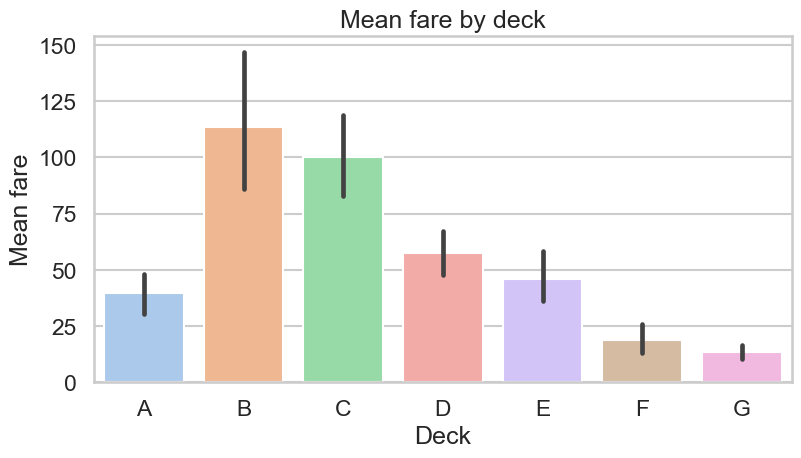

      count        mean    median
deck                             
A        15   39.623887  35.50000
B        47  113.505764  80.00000
C        59  100.151341  83.47500
D        33   57.244576  53.10000
E        32   46.026694  45.18125
F        13   18.696792  13.00000
G         4   13.581250  13.58125


In [ ]:
# N05
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="deck", y="fare", hue="deck", palette="pastel",
            legend=False,
            errorbar=("ci", 95), # Confidence Interval, 신뢰구간 (= 평균에 대한 95% 신뢰구간) # n_boot = 5000
            seed=42,
            ax=ax)
ax.set(title="Mean fare by deck", xlabel="Deck", ylabel="Mean fare")
plt.show()
print(df.groupby("deck", observed=True)["fare"].agg(["count", "mean", "median"]))

**결과를 읽을 때**

막대는 갑판별 평균 요금이고 오차막대는 평균의 추정 불확실성입니다. deck이 알려진 203명의 자료를 요약했습니다.

### 평균 대신 중앙값을 비교

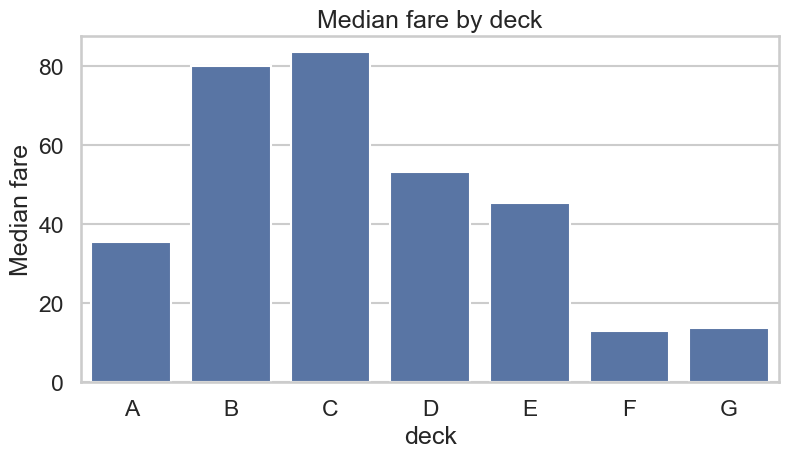

In [9]:
# N05
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="deck", y="fare", estimator="median", errorbar=None, ax=ax) # estimator = 추정량
ax.set(title="Median fare by deck", ylabel="Median fare")
plt.show()

**결과를 읽을 때**

중앙값은 비싼 요금 몇 개의 영향을 평균보다 덜 받습니다. 갑판별 평균과 중앙값이 얼마나 다른지 비교하세요.

## N06 · bar_label: 막대 위에 숫자 표시

bar_label은 막대 높이를 숫자로 붙이는 Matplotlib의 Axes 메서드입니다.

**질문:** 평균 금액을 그래프에서 바로 읽게 하려면 어떻게 할까요?

### 갑판별 평균 요금을 숫자로 표시

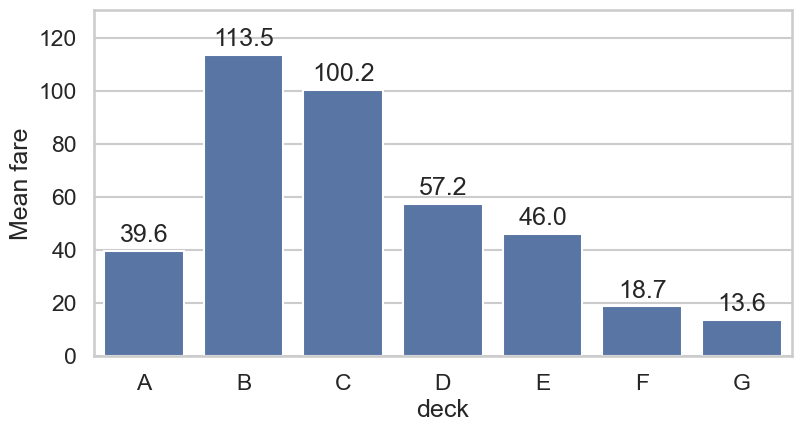

In [10]:
# N06
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="deck", y="fare", errorbar=None, ax=ax)

for bars in ax.containers: # ax.containers = 막대 묶음 등의 객체가 들어 있는 리스트
    ax.bar_label(bars, fmt="%.1f", padding=3)

ax.set(ylabel="Mean fare")
ax.margins(y=0.15)
plt.show()

### 승객 수를 정수로 표시

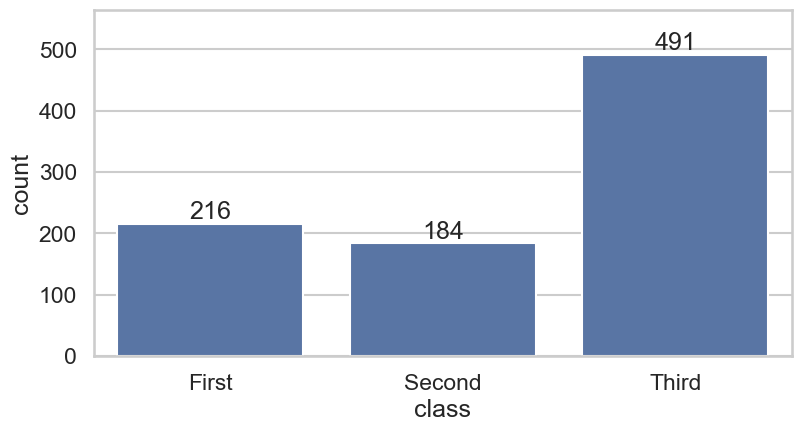

In [11]:
# N06
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="class", ax=ax)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f")

ax.margins(y=0.15)
plt.show()

**결과를 읽을 때**

정수에는 소수 자릿수가 필요 없으므로 %.0f를 사용합니다.

## N07 · histplot: 연령 구간별 인원수

히스토그램(histplot)은 수치를 구간(bin)으로 나누고 각 구간에 들어간 기록 수를 셉니다.

**질문:** 나이가 알려진 승객은 어떤 연령대에 많을까요?

### 5세 단위로 연령 분포 확인

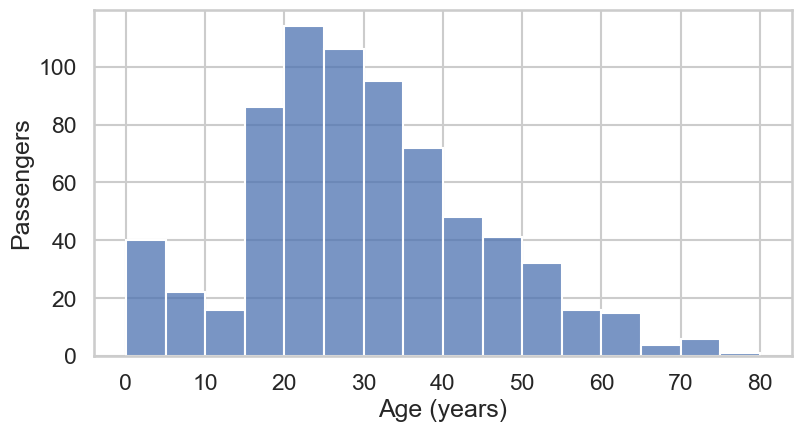

나이가 있는 기록: 714


In [ ]:
# N07
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))

#여기가 핵심
sns.histplot(data=df, x="age", binwidth=5, binrange=(0, 80), ax=ax)
#여기도 보기
ax.set(xlabel="Age (years)", ylabel="Passengers")
plt.show()
print("나이가 있는 기록:", df["age"].count())

**결과를 읽을 때**

나이가 있는 714명을 5세 구간으로 셉니다. 20~30대 부근에 기록이 많이 모입니다.

### 구간 폭 2세와 10세 비교

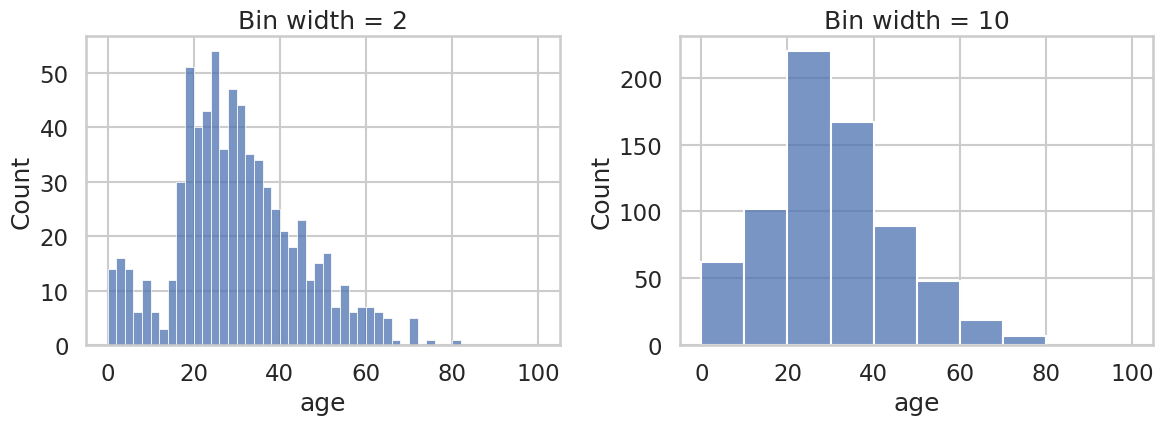

In [ ]:
# N07
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

#squeeze가 뭐지?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, squeeze=False) # sharex=True : 여러 그래프가 x축의 범위와 눈금 설정을 공유
sns.histplot(data=df, x="age", binwidth=2, binrange=(0, 100), ax=axes[0,0])
sns.histplot(data=df, x="age", binwidth=10, binrange=(0, 80), ax=axes[0,1])

axes[0,0].set_title("Bin width = 2")
axes[0,1].set_title("Bin width = 10")

plt.tight_layout()
plt.show()

**결과를 읽을 때**

2세 구간은 작은 차이를, 10세 구간은 큰 연령 흐름을 보여 줍니다. 구간이 넓으면 한 막대에 더 많은 기록이 들어갑니다.

## N08 · histplot: 성별 분포와 KDE

커널 밀도 추정(KDE)은 관측값 주변을 부드럽게 퍼뜨려 분포의 모양을 추정합니다.

**질문:** 남성의 막대가 높다면 남성이 특정 나이에 더 집중되어 있다는 뜻일까요?

### 성별 인원수와 KDE 함께 보기

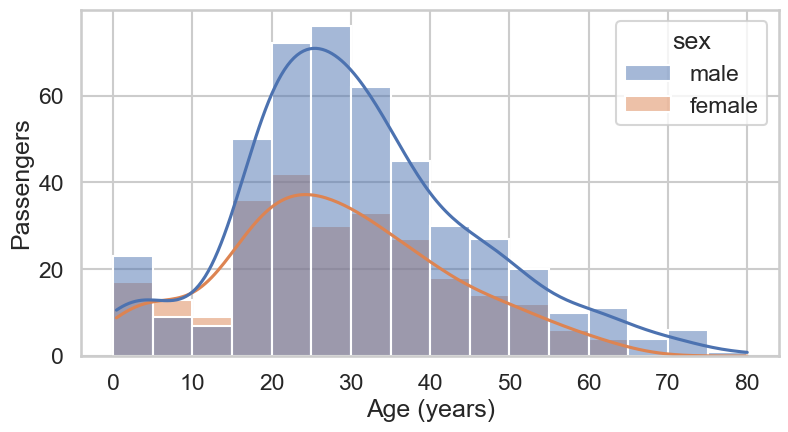

In [ ]:
# N08
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
#kde 옵션
#hue 옵션
sns.histplot(data=df, x="age", hue="sex", binwidth=5,
             binrange=(0, 80), kde=True, ax=ax)
ax.set(xlabel="Age (years)", ylabel="Passengers")
plt.show()

**결과를 읽을 때**

성별 기록 수와 분포를 함께 봅니다. 이 KDE는 빈도 눈금에 맞춰 그린 곡선입니다.

### 집단 크기의 영향을 줄이고 분포 형태 비교

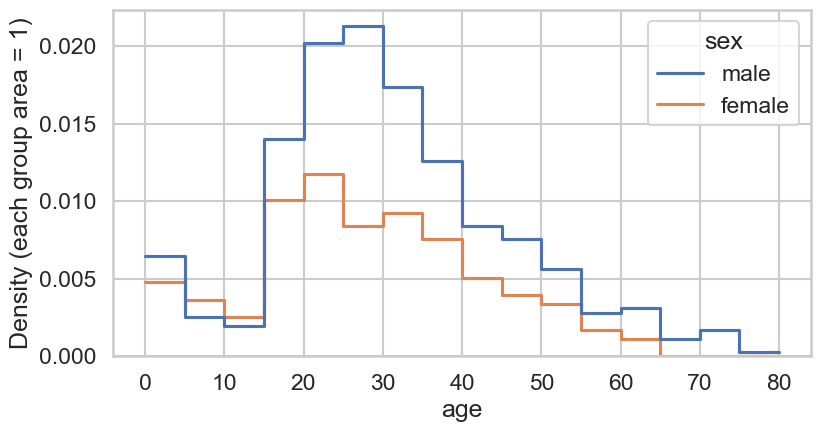

sex
female    261
male      453
Name: age, dtype: int64


In [1]:
# N08
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df, x="age", hue="sex", binwidth=5,
             binrange=(0, 80), stat="density",
             element="step", fill=False, ax=ax)

ax.set(ylabel="Density (each group area = 1)")
plt.show()
print(df.groupby("sex")["age"].count())

## N09 · histplot: bars, step, poly

element는 같은 구간별 빈도를 막대, 계단형 윤곽, 다각선으로 표현하는 옵션입니다.

**질문:** 겹친 두 히스토그램의 윤곽을 더 쉽게 비교하려면?

### poly로 두 분포의 윤곽 비교

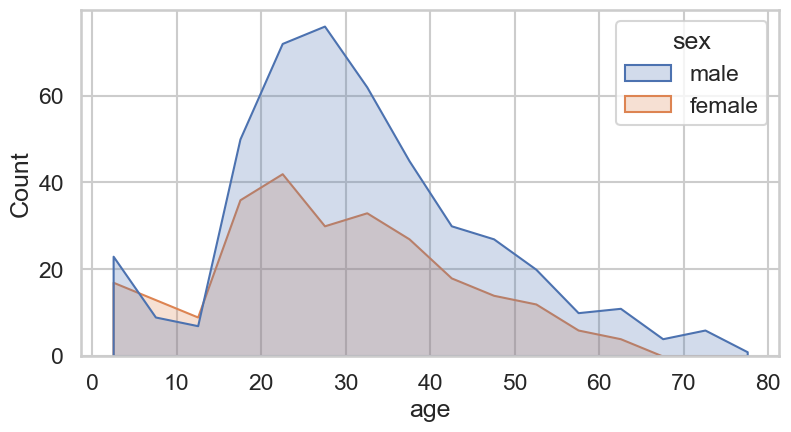

In [2]:
# N09
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df, x="age", hue="sex", binwidth=5,
             binrange=(0, 80), element="poly", ax=ax)
plt.show()

## N10 · displot: 분포와 패널을 함께 만들기

분포 그래프(displot)는 kind로 표현을 고르고 그림과 패널 배치까지 만듭니다.

**질문:** 객실 등급마다 승객의 연령 분포가 어떻게 다를까요?

### 등급별 KDE 비교

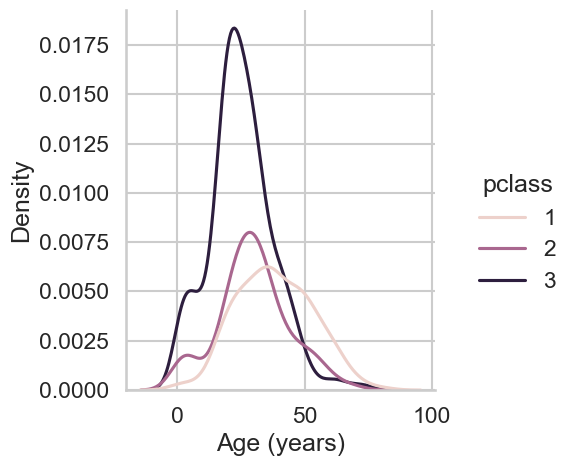

In [3]:
# N10
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.displot(data=df, x="age", hue="pclass", kind="kde")
g.set_axis_labels("Age (years)", "Density")
plt.show()

## N11 · displot: 등급별 밀도 누적

누적 밀도는 집단의 기여분을 위로 쌓습니다. 각 집단은 띠의 두께로 읽습니다.

**질문:** 전체 연령 분포에서 어느 등급이 많이 기여할까요?

### 등급별 기여분을 쌓아 표시

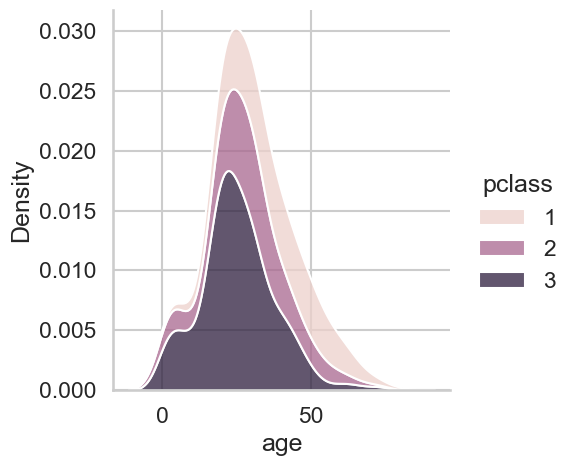

In [ ]:
# N11
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

#multiple
g = sns.displot(data=df, x="age", hue="pclass", kind="kde", multiple="stack")
plt.show()

**결과를 읽을 때**

띠의 위 경계에서 아래 경계를 뺀 두께가 해당 집단의 밀도 기여분입니다. 가장 위 선은 누적값입니다.

### 곡선의 매끄러움이 해석에 미치는 영향

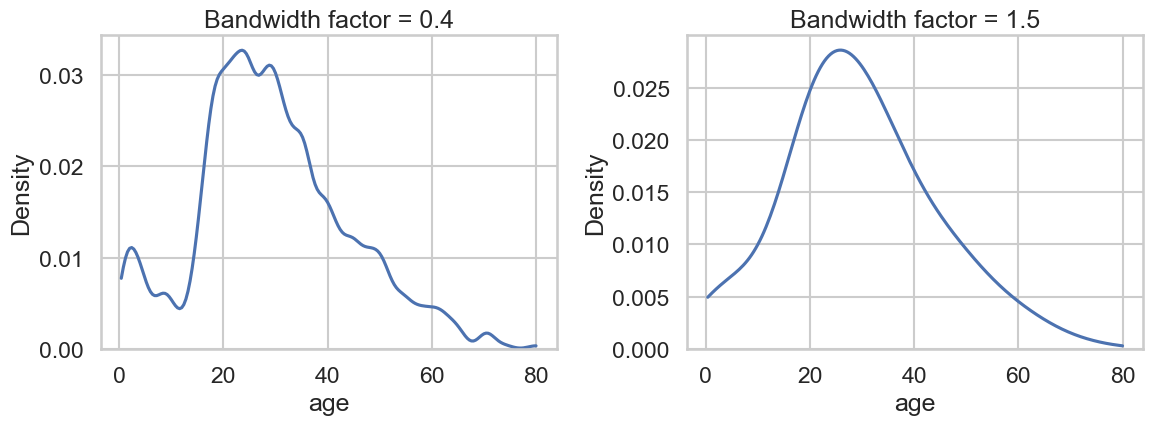

In [5]:
# N11
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

sns.kdeplot(data=df, x="age", bw_adjust=0.4, cut=0, ax=axes[0]) # bw_adjust = 대역폭, cut = 표시 범위
sns.kdeplot(data=df, x="age", bw_adjust=1.5, cut=0, ax=axes[1])

axes[0].set_title("Bandwidth factor = 0.4")
axes[1].set_title("Bandwidth factor = 1.5")
plt.tight_layout()
plt.show()

**결과를 읽을 때**

bw는 bandwidth(대역폭)입니다. 크게 하면 더 넓게 평균화해 작은 요철이 줄어듭니다.

## N12 · FacetGrid: 조건별 패널과 map

조건별 격자(FacetGrid)는 먼저 빈 칸을 만들고 map으로 각 칸에 같은 함수를 적용합니다.

**질문:** 등급·생존 여부를 맞춰도 남녀의 나이 분포가 다를까요?

### 빈 격자를 만든 뒤 곡선 채우기

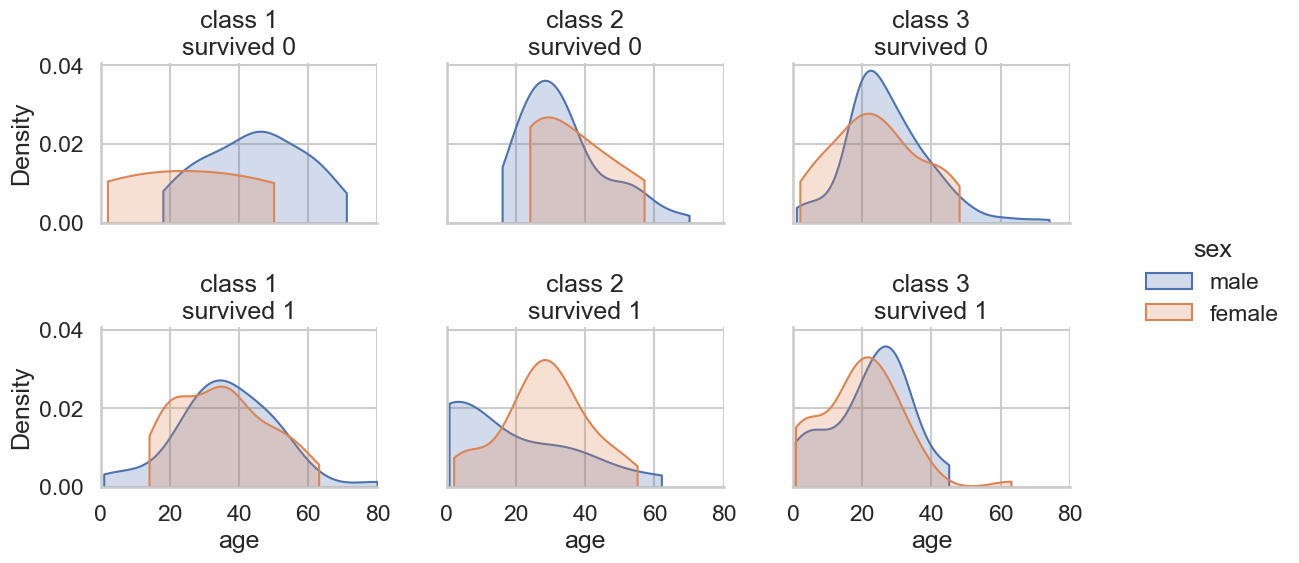

pclass  survived  sex   
1       0         female      3
                  male       61
        1         female     82
                  male       40
2       0         female      6
                  male       84
        1         female     68
                  male       15
3       0         female     55
                  male      215
        1         female     47
                  male       38
Name: age, dtype: int64


In [ ]:
# N12
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

#빈 틀 만들기
g = sns.FacetGrid(df,
                  col="pclass", # 객실 등급 1·2·3에 따라 3개의 열을 만듭니다.
                  row="survived", # 사망(0)·생존(1)에 따라 2개의 행을 만듭니다.
                  hue="sex", # 각 칸 안에서 남녀를 색으로 구분합니다.
                  height=2.5, aspect=1.1, xlim=(0, 80) # 칸 높이 2.5 종횡비 1.1 / 모든 칸의 x축을 0~80세로 설정
                  )

g.map(sns.kdeplot, "age", fill=True, cut=0) # map() = 각 칸에 같은 함수를 적용합니다
g.add_legend()
g.set_titles("class {col_name}\nsurvived {row_name}")
g.figure.set_size_inches(14, 6)
g.figure.subplots_adjust(hspace=0.65, wspace=0.25)

plt.show()
print(df.groupby(["pclass", "survived", "sex"])["age"].count())

**결과를 읽을 때**

먼저 2행×3열의 조건을 만들고 map으로 각 칸의 나이를 그립니다. 색은 그 조건 안의 성별입니다.

### 먼저 빈 패널만 확인

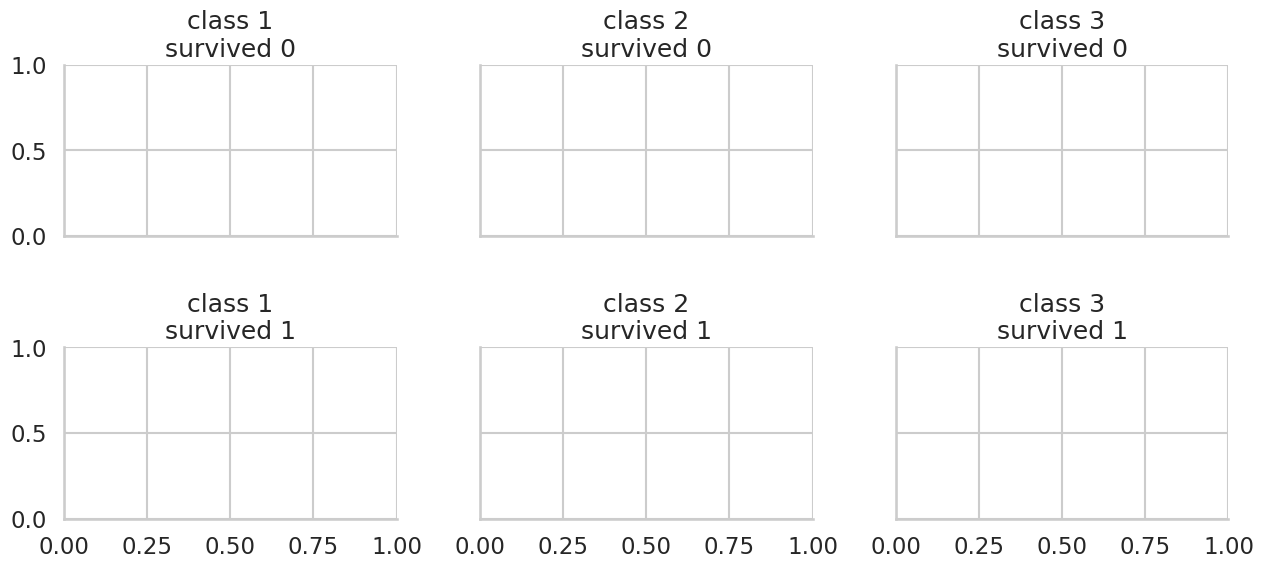

In [85]:
# N12
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.FacetGrid(df, col="pclass", row="survived", hue="sex", height=2.5)

g.set_titles("class {col_name}\nsurvived {row_name}")
g.figure.set_size_inches(14, 6)
g.figure.subplots_adjust(hspace=0.65, wspace=0.25)

plt.show()

## N13 · boxplot: 중앙값과 사분위범위

상자그림(boxplot)은 Q1·중앙값·Q3, 수염, 수염 밖 관측값을 요약합니다.

**질문:** 대부분의 요금은 낮은데 일부 고액 요금이 평균을 올렸을까요?

### 전체 요금과 0~100 확대 비교

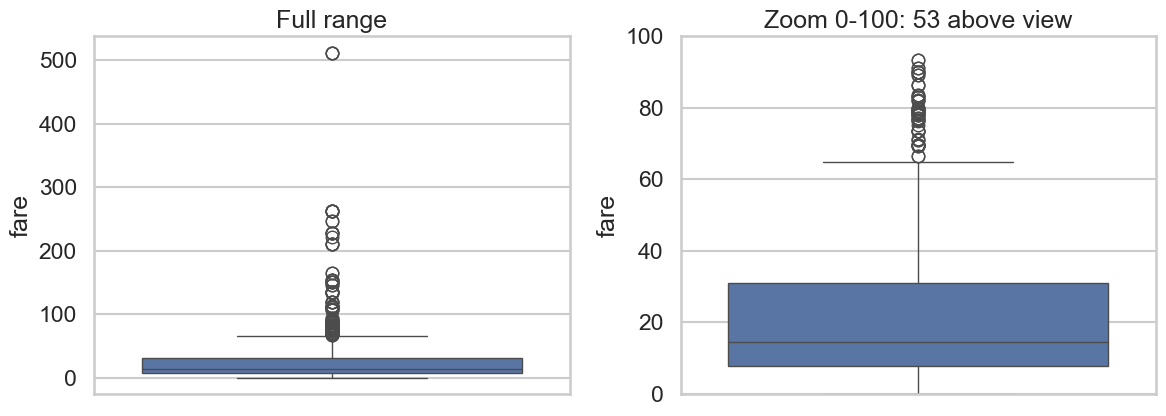

확대에서 보이지 않는 기록: 53
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64


In [1]:
# N13
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in axes:
    sns.boxplot(data=df, y="fare", ax=ax)

axes[0].set_title("Full range")

axes[1].set_ylim(0, 100)
hidden = (df["fare"] > 100).sum()
axes[1].set_title(f"Zoom 0-100: {hidden} above view")

plt.tight_layout()
plt.show()
print("확대에서 보이지 않는 기록:", hidden)
print(df["fare"].describe())

## N14 · boxplot: 객실 등급별 요금 비교

x에 범주를 지정하면 집단마다 상자를 만들어 중앙값과 퍼짐을 비교합니다.

**질문:** 1등급 요금이 높다는 말만으로 요금 분포를 충분히 설명할 수 있을까요?

### 등급별 요금의 중심과 퍼짐

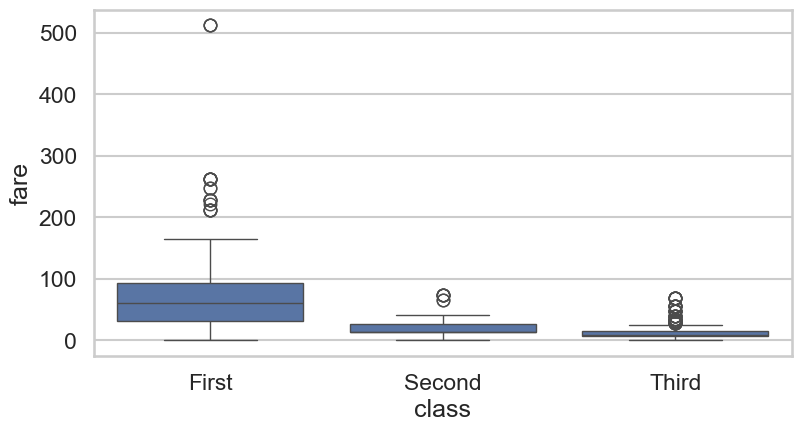

        count   median       mean
class                            
First     216  60.2875  84.154687
Second    184  14.2500  20.662183
Third     491   8.0500  13.675550


In [2]:
# N14
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="class", y="fare", ax=ax)
plt.show()
print(df.groupby("class", observed=True)["fare"].agg(["count", "median", "mean"]))

## N15 · violinplot: 분포의 모양까지 비교

바이올린 그래프(violinplot)는 KDE를 좌우 대칭으로 그려 값이 몰린 구간을 보여 줍니다.

### 전체 바이올린과 낮은 요금 확대

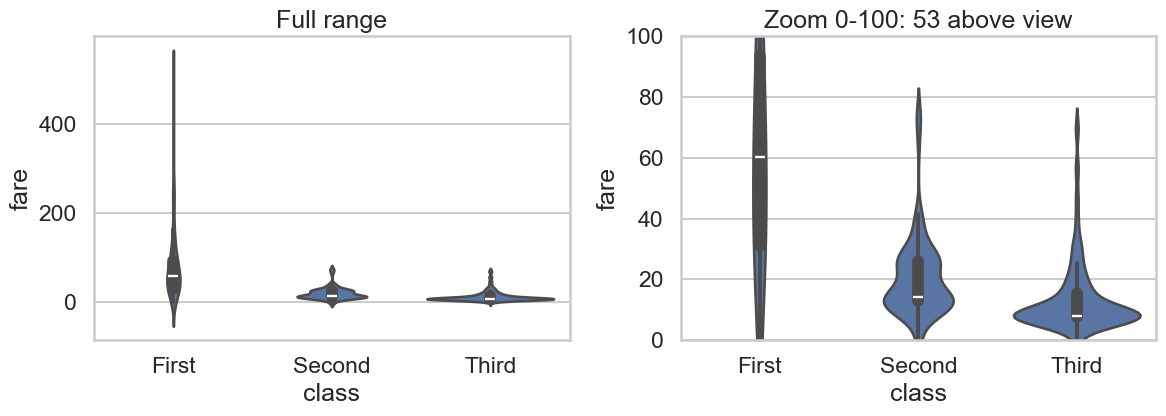

확대에서 보이지 않는 기록: 53


In [3]:
# N15
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in axes:
    sns.violinplot(data=df, x="class", y="fare", ax=ax)
axes[0].set_title("Full range")

axes[1].set_ylim(0, 100)
hidden = (df["fare"] > 100).sum()
axes[1].set_title(f"Zoom 0-100: {hidden} above view")
plt.tight_layout()
plt.show()
print("확대에서 보이지 않는 기록:", hidden)

## N16 · swarmplot: 실제 관측값을 점으로 보기

스웜 그래프(swarmplot)는 같은 범주의 점이 겹치지 않도록 가로 위치를 벌려 놓습니다.

**질문:** 높은 요금은 정말 몇 개의 기록에만 나타날까요?

### 요금 기록을 점 하나씩 확인

이 셀은 점이 너무 많을 때의 한계를 보여 줍니다. Titanic에는 같은 요금이 반복되어 일부 점을 겹치지 않게 벌릴 공간이 부족합니다. “cannot be placed” 경고의 비율은 배치하지 못한 점의 비율입니다. 경고 출력은 그대로 두고, 앞의 tips 예제 또는 stripplot·histplot과 비교하세요.

/Users/taeyoungkim/workspace/data_analysis_lecture/.venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 47.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/taeyoungkim/workspace/data_analysis_lecture/.venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/taeyoungkim/workspace/data_analysis_lecture/.venv/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 52.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


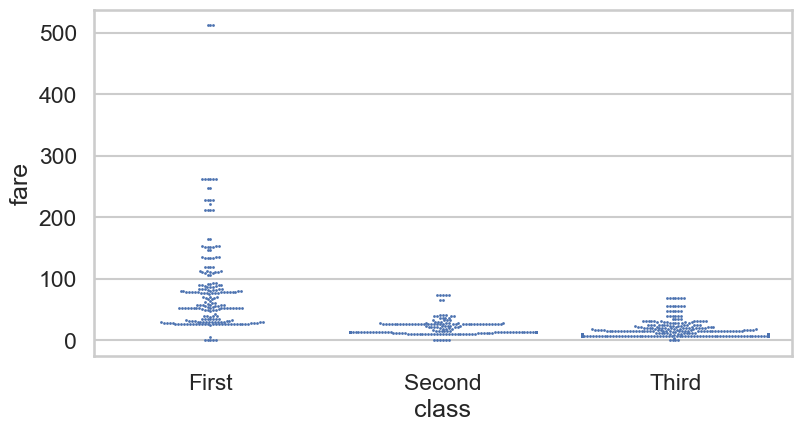

In [4]:
# N16
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.swarmplot(data=df, x="class", y="fare", size=2, ax=ax)
plt.show()

# Warning 내용 : 비슷한 운임의 승객이 너무 많아서, 일부 점을 서로 겹치지 않게 배치할 공간이 부족하다

**결과를 읽을 때**

점 하나는 승객 한 명입니다. 반복 요금이 많아 벌려 놓을 공간이 부족하면 경고가 나며, 이 상황에서는 더 작은 점이나 다른 그래프가 유리합니다.

## N17 · scatterplot: 두 수치의 관계

산점도(scatterplot)는 한 관측의 두 수치를 x·y 위치에 표시합니다.

**질문:** 나이가 많은 승객일수록 요금도 높았을까요?

### 나이와 요금의 관계 확인

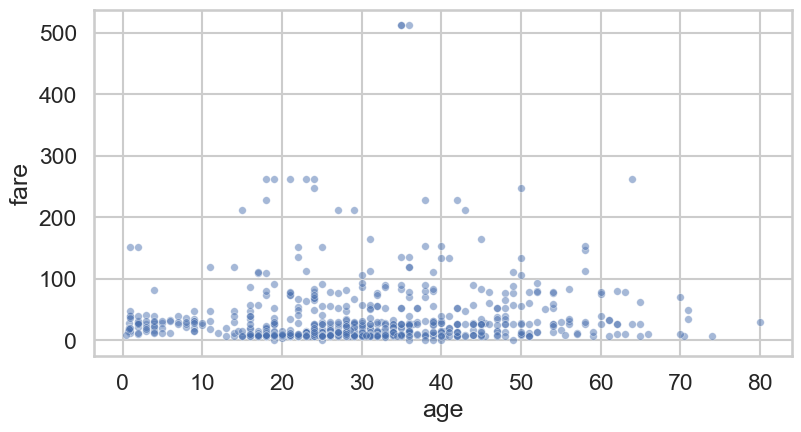

사용 가능한 기록: 714


In [5]:
# N17
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df, x="age", y="fare", alpha=0.5, s=30, ax=ax) # alpha : 점의 불투명도 (겹치는 곳도 보일 수 있게), s : 점의 크기
plt.show()
print("사용 가능한 기록:", len(df.dropna(subset=["age", "fare"])))

**결과를 읽을 때**

점이 뚜렷한 한 직선 주변에 몰려 있는지 확인하세요.

## N18 · scatterplot: 색과 모양으로 집단 표시

hue와 style은 점의 위치를 유지하면서 범주를 색과 모양으로 구분합니다.

**질문:** 같은 나이·요금 위치의 점이 어느 집단인지 어떻게 구분할까요?

### 성별만 색으로 추가

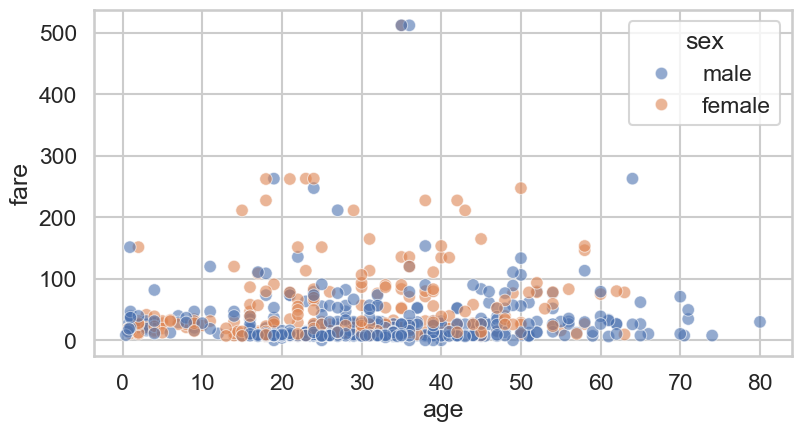

In [6]:
# N18
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df, x="age", y="fare", hue="sex", alpha=0.6, ax=ax)
plt.show()

### who를 모양으로 추가

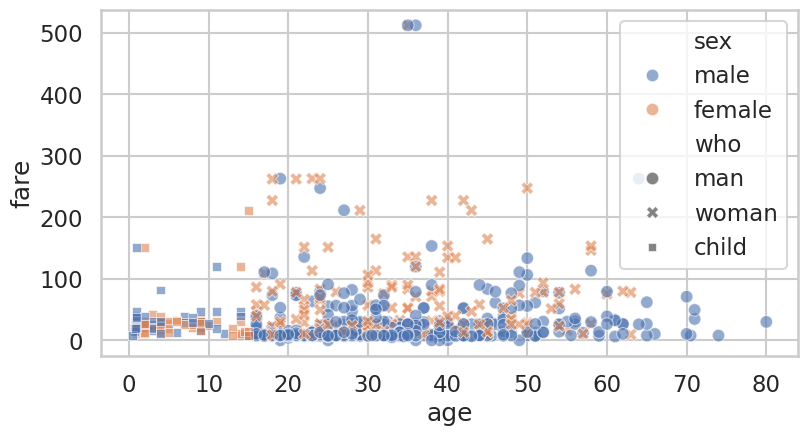

    age     sex    who
0  22.0    male    man
1  38.0  female  woman
2  26.0  female  woman
3  35.0  female  woman
4  35.0    male    man


In [101]:
# N18
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df, x="age", y="fare", hue="sex", style="who", alpha=0.6, ax=ax)
plt.show()
print(df[["age", "sex", "who"]].head())

**결과를 읽을 때**

범례에서 sex는 색, who는 모양에 대응합니다. 이 자료의 child는 16세 미만으로 분류되어 낮은 나이 쪽에 나타납니다.

**정리**

- 같은 나이·요금 좌표에 성별 색을 더해 집단을 구별합니다.
- style="who"를 더하면 man·woman·child가 다른 모양으로 표시됩니다.
- who는 나이와 성별에서 만든 범주이므로 그 기준도 함께 읽습니다.

## N19 · scatterplot: 점 크기에 수량 연결

size는 변수 값에 따라 점의 크기를 정합니다. 크기는 수량이나 정도를 표현할 때 자연스럽습니다.

**질문:** man·woman·child에 큰 점과 작은 점을 주면 어떤 오해가 생길까요?

### 범주를 크기로 표시한 예 확인

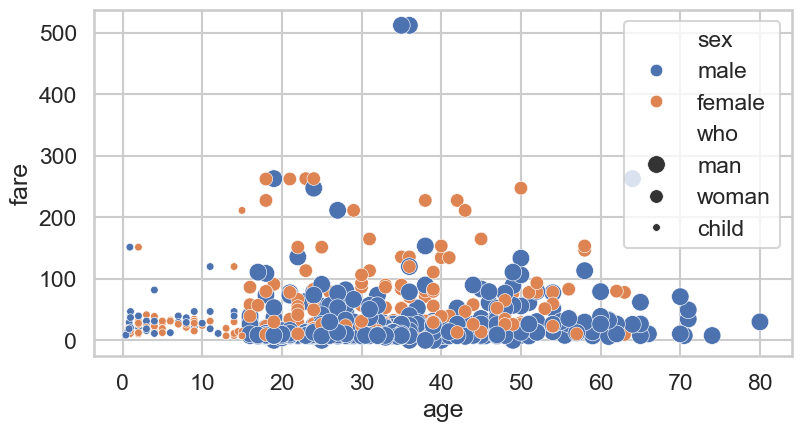

In [7]:
# N19
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df, x="age", y="fare", hue="sex", size="who", sizes=(30, 160), ax=ax)
plt.show()

**결과를 읽을 때**

who는 수량 순서가 없는 범주입니다. 문법은 가능하지만 큰 점을 많은 사람으로 오해하기 쉬워 모양 구분이 더 자연스럽습니다.

**정리**

- 이 예제는 who 범주마다 다른 크기를 배정합니다.
- 크기는 많고 적음으로 읽히므로 순서 없는 who에는 어울리지 않습니다.
- 다음 예제처럼 식사 인원수라는 숫자 변수에 크기를 연결해 봅시다.

## N20 · lmplot: 회귀선으로 관계 요약

선형 모형 그래프(lmplot)는 점과 선형 회귀선을 그려 평균적인 관계를 요약합니다.

**질문:** 전체 관계와 집단별 관계를 같은 한 줄로 설명해도 될까요?

### 전체 승객의 회귀선

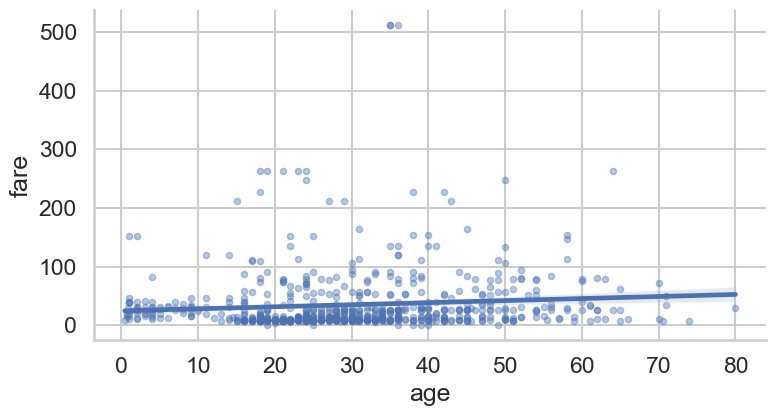

In [8]:
# N20
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.lmplot(data=df, x="age", y="fare", height=4.5, aspect=1.8,
              seed=42, scatter_kws={"alpha": 0.4, "s": 20}) # lmplot = Linear Model Plot (선형 모형 플롯)
plt.show()

**결과를 읽을 때**

선은 완만히 증가하지만 요금의 산포가 큽니다. 선과 점의 거리를 함께 보아 관계의 강도를 판단하세요.

- 선형 모형 > 나이와 운임의 관계를 직선 하나로 요약한 것
- 선이 오른쪽으로 올라감 → 나이가 많을수록 운임이 높은 경향

### 생존 여부별로 다른 회귀선 추정

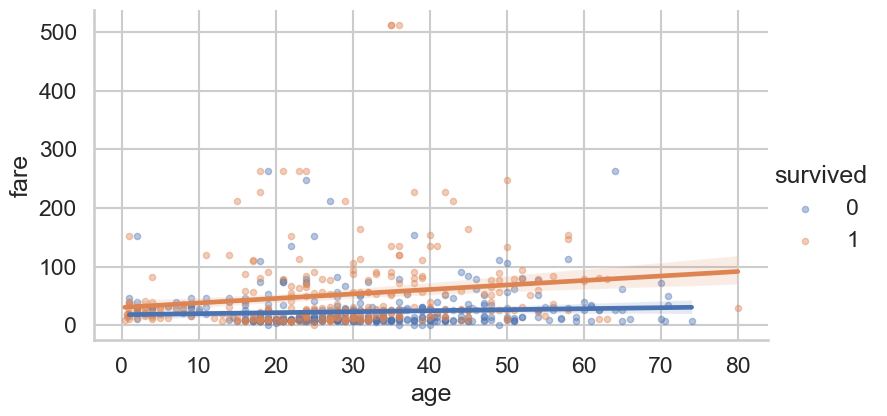

In [9]:
# N20
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.lmplot(data=df, x="age", y="fare", hue="survived",
              height=4.5, aspect=1.8, seed=42,
              scatter_kws={"alpha": 0.4, "s": 20})
plt.show()

**결과를 읽을 때**

생존 집단과 사망 집단 각각의 자료로 회귀선을 계산합니다. 전체 한 선에서 가려졌던 집단별 관계를 비교할 수 있습니다.

**정리**

- 전체 회귀선은 완만히 증가하지만 점들은 넓게 흩어져 있습니다.
- 회귀선과 신뢰구간 띠로 평균적인 관계와 추정의 불확실성을 봅니다.
- 회귀선이 보여 주는 관계만으로 인과관계를 단정하지 않습니다.

## N21 · jointplot: 관계와 각 변수의 분포

결합 그래프(jointplot)는 가운데 두 변수의 상관 관계 그래프를, 위·오른쪽에 각 변수의 분포를 배치합니다.

**질문:** 점이 몰린 위치와 각 변수의 분포를 한 번에 확인하려면?

### 산점도와 두 주변 히스토그램

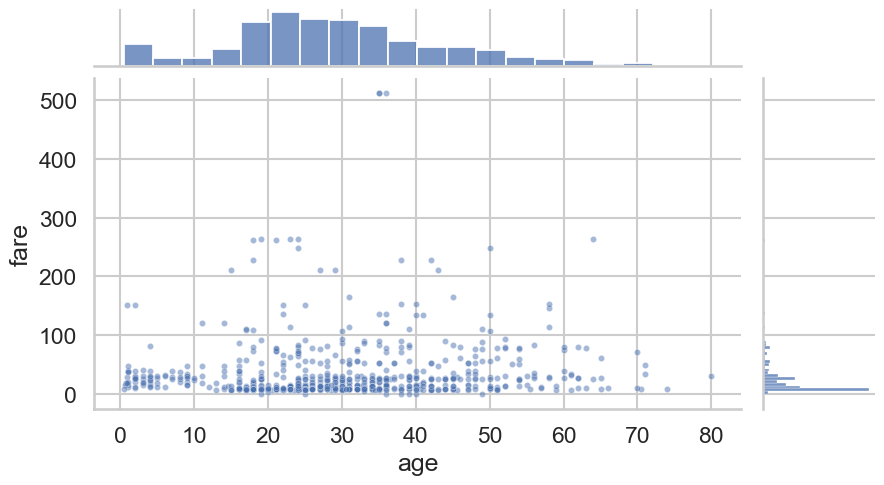

In [10]:
# N21
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.jointplot(data=df, x="age", y="fare", height=6,
                 joint_kws={"alpha": 0.5, "s": 20})
g.figure.set_size_inches(10, 5)
plt.show()

**결과를 읽을 때**

가운데는 나이·요금의 조합, 위는 나이 분포, 오른쪽은 요금 분포입니다. 낮은 요금에 몰린 모양이 두 위치에서 연결됩니다.

### 성별을 구분한 jointplot

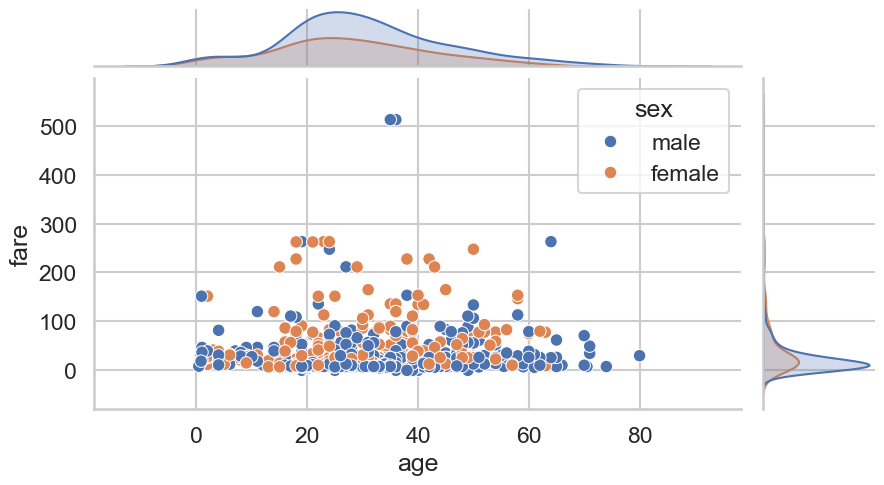

In [11]:
# N21
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.jointplot(data=df, x="age", y="fare", hue="sex", height=6)
g.figure.set_size_inches(10, 5)
plt.show()

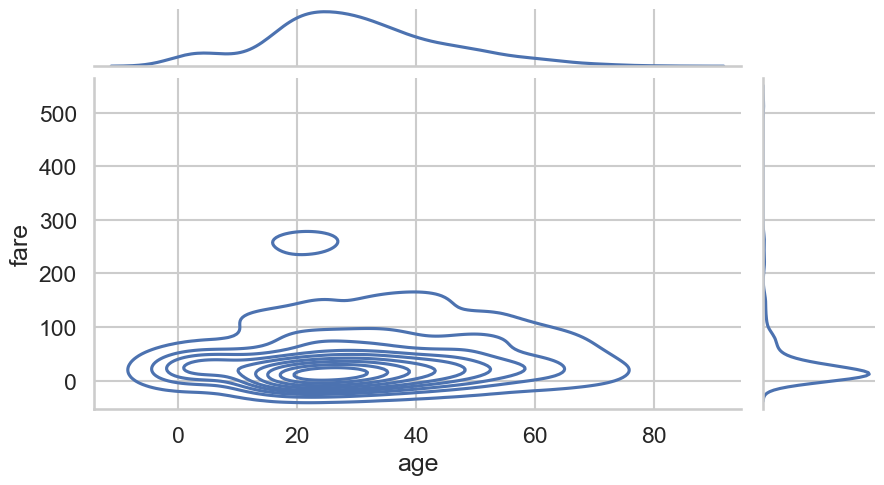

In [12]:
# N21
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

g = sns.jointplot(data=df, x="age", y="fare", kind='kde')
g.figure.set_size_inches(10, 5)
plt.show()

## N22 · heatmap: 상관계수를 색으로 요약

히트맵(heatmap)은 표의 수치를 색으로 표현합니다. 여기서는 −1~1의 상관계수를 넣습니다.

**질문:** 어떤 변수 조합을 산점도로 더 확인할 가치가 있을까요?

### 상관계수 표를 색으로 표시

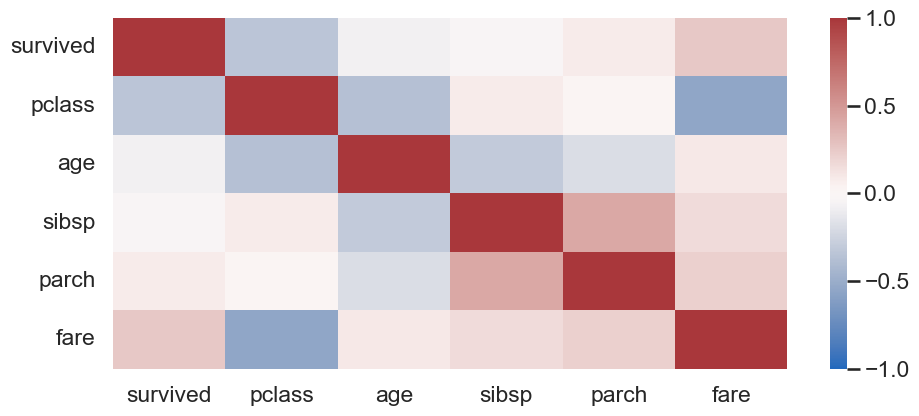

          survived  pclass   age  sibsp  parch  fare
survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
sibsp        -0.04    0.08 -0.31   1.00   0.41  0.16
parch         0.08    0.02 -0.19   0.41   1.00  0.22
fare          0.26   -0.55  0.10   0.16   0.22  1.00


In [13]:
# N22
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr = df[cols].corr() # 상관계수를 계산

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(corr,
            cmap="vlag", # 음수는 푸른색, 0 부근은 밝은색, 양수는 붉은색으로 표현하는 색상표
            vmin=-1,
            vmax=1,
            center=0, # 색이 나뉘는 중심을 0으로 설정
            ax=ax)
plt.tight_layout() # 축 이름 등이 잘리지 않도록 배치를 조정
plt.show()

print(corr.round(2))

**결과를 읽을 때**

pclass와 fare가 음의 상관으로 보입니다. 등급 번호가 커질수록 요금이 낮아지는 경향을 뜻합니다.

### 수치를 함께 읽고 관계를 검산

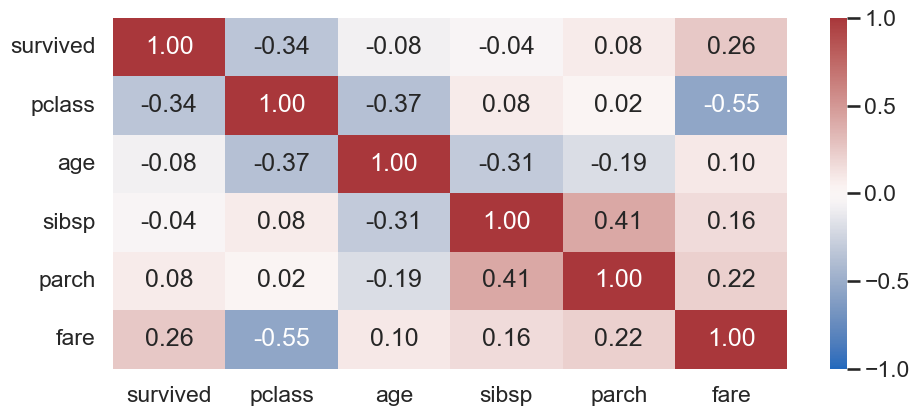

나이·요금이 모두 있는 기록: 714


In [14]:
# N22
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")
df = sns.load_dataset("titanic")

cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(10, 4.5))

sns.heatmap(corr,
            annot=True, # 상관계수 숫자를 표시(Annotation : 주석)
            fmt=".2f",
            cmap="vlag",
            vmin=-1, vmax=1, center=0, square=False, ax=ax)
plt.tight_layout()
plt.show()
print("나이·요금이 모두 있는 기록:", len(df[["age", "fare"]].dropna()))

**결과를 읽을 때**

숫자를 함께 읽으면 pclass·fare는 약 −0.55, age·fare는 약 0.10입니다. 각 쌍에 값이 모두 있는 기록으로 계산합니다.

**정리**

- 대각선은 1이고 위·아래 삼각형에는 같은 관계가 반복됩니다.
- pclass와 fare는 음의 관계입니다. 등급 번호가 클수록 요금이 낮아집니다.
- 상관은 선형 관계의 요약이며 인과관계의 증거는 아닙니다.

# 확인 과제 · 한 자료를 여러 방식으로 설명하기

Seaborn의 예제 자료 하나를 선택해 **막대그래프·산점도·boxplot·violinplot·jointplot**을 만들고, **다른 그래프 두 종류**를 추가하세요. 아래는 `penguins`로 시작하는 예입니다. 다른 자료를 선택해도 됩니다.

## Q01 · 자료와 분석 질문 정하기

자료를 불러와 shape, head(), isna().sum()을 출력하세요. 분석할 열과 단위를 정하세요.

In [ ]:
# Q01
# 데이터 전처리 과정은 코드 짤 줄 알아야 함
import seaborn as sns
df = sns.load_dataset("penguins")
print(df.head())
# 아래에 크기와 결측 확인 코드를 작성하세요.

**해석 질문:** 무슨 자료인가요? 어떤 두 가지 질문을 분석하고 싶나요?

**답:**

여기에 작성하세요.

## Q02 · 막대그래프와 산점도

종별 개수 또는 평균 몸무게 막대그래프와, 두 수치의 산점도를 만드세요. 두 코드는 각각 독립적으로 실행되게 작성하세요.

In [ ]:
# Q02
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset("penguins")
# 막대그래프를 작성하고 plt.show()로 출력하세요.

**산점도 코드**: 앞 코드의 변수에 의존하지 않고 아래에서 다시 자료를 불러와 그리세요.

In [ ]:
# Q02
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset("penguins")
# 산점도를 작성하고 plt.show()로 출력하세요.

**해석 질문:** 막대 높이는 개수인가요, 평균인가요? 산점도는 어떤 관계를 보여 주나요?

**답:**

여기에 작성하세요.

## Q03 · boxplot·violinplot·jointplot

같은 자료에 boxplot, violinplot, jointplot을 적용하세요. 필요하면 코드 셀을 추가하세요.

In [ ]:
# Q03
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset("penguins")
# 세 종류의 그래프를 작성하세요. 각 그래프 뒤에 plt.show()를 넣으세요.

**해석 질문:** 상자와 바이올린에서 얻은 정보는 어떻게 다른가요? jointplot의 가운데와 주변은 각각 무엇인가요?

**답:**

여기에 작성하세요.

## Q04 · 두 종류 더 탐색하기

위에서 쓰지 않은 그래프 두 종류를 골라 적용하세요. histplot, ecdfplot, heatmap, pairplot 등을 선택할 수 있습니다.

In [ ]:
# Q04
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset("penguins")
# 선택한 그래프 두 종류를 작성하세요.

**해석 질문:** 추가한 두 그래프를 고른 이유와 새로 알게 된 내용을 각각 적으세요.

**답:**

여기에 작성하세요.

## 참고 자료

- [Seaborn 함수의 담당 범위](https://seaborn.pydata.org/tutorial/function_overview.html)
- [분포 시각화](https://seaborn.pydata.org/tutorial/distributions.html)
- [오차막대와 통계 추정](https://seaborn.pydata.org/tutorial/error_bars.html)
- [회귀 모형 시각화](https://seaborn.pydata.org/tutorial/regression.html)
- [0.13 변경 사항](https://seaborn.pydata.org/whatsnew/v0.13.0.html)
- [Plotly graph_objects](https://plotly.com/python/graph-objects/)
- [Plotly 추세선](https://plotly.com/python/linear-fits/)
- [예제 데이터](https://github.com/mwaskom/seaborn-data)
